simple and multiple linear regression: building moels, checking assumptions, and evaluating using R2 and RMSE

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

In [ ]:
from google.colab import files
import pandas as pd

uploaded = files.upload()

Saving housing_clean.csv to housing_clean.csv


In [ ]:
df = pd.read_csv('housing_clean.csv')
df.head()

,Area,Rooms,Age,Location_Score,Price
0,778,1,6,3,5081030
1,2148,4,27,8,11863210
2,1909,3,3,5,11371453
3,1478,3,16,3,9079771
4,1466,3,14,4,7502204


In [ ]:
X_simple = df[['Area']]
y=df['Price']

X_train, X_test, y_train, y_test = train_test_split(
    X_simple, y, test_size=0.2, random_state=42
)

model_simple = LinearRegression()
model_simple.fit(X_train, y_train)
pred_simple = model_simple.predict(X_test)

print('Simple Regression')
print('R2=', round(r2_score(y_test, pred_simple), 3))
print('RMSE:', round(np.sqrt(mean_squared_error(y_test, pred_simple)), 2))

Simple Regression
R2= 0.939
RMSE: 809207.7


In [ ]:
X_multi = df[['Area', 'Rooms', 'Age', 'Location_Score']]
y=df['Price']

X_train2, X_test2, y_train2, y_test2 = train_test_split(
    X_multi, y, test_size=0.2, random_state=42
)

model_multi = LinearRegression()
model_multi.fit(X_train2, y_train2)
pred_multi = model_multi.predict(X_test2)

print('Multiple Regression')
print('R2=', round(r2_score(y_test2, pred_multi), 3))
print('RMSE:', round(np.sqrt(mean_squared_error(y_test2, pred_multi)), 2))

Multiple Regression
R2= 0.977
RMSE: 495063.19


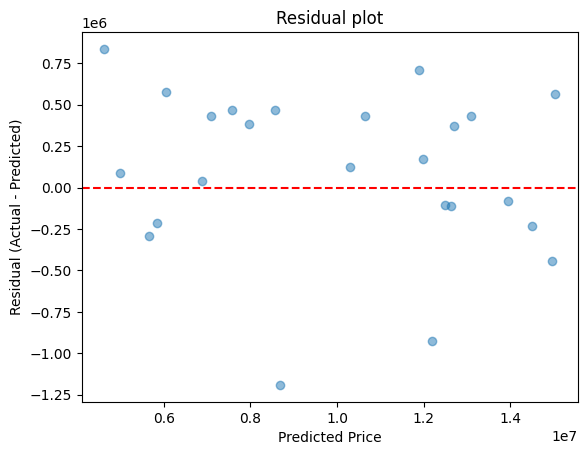

In [ ]:
residuals = y_test2 - pred_multi

plt.scatter(pred_multi, residuals, alpha=0.5)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Predicted Price')
plt.ylabel('Residual (Actual - Predicted)')
plt.title('Residual plot')
plt.show()